MENDETEKSI MISSING VALUE DAN MENGUBAH TIPE DATA WAKTU


In [3]:
import pandas as pd

df_products = pd.read_csv('olist_products_dataset.csv')
df_orders = pd.read_csv('olist_orders_dataset.csv')

df_products.rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'
}, inplace=True)

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_columns:
    df_orders[col] = pd.to_datetime(df_orders[col], errors='coerce')

print("Missing Values di tabel Produk: ")
print(df_products.isnull().sum())
print("\n Missing Values di tabel Orders: ")
print(df_orders.isnull().sum())

Missing Values di tabel Produk: 
product_id                      0
product_category_name         610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

 Missing Values di tabel Orders: 
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


MENANGANI MISSING VALUE

In [4]:
df_products['product_category_name'] = df_products['product_category_name'].fillna('unknown')

numeric_cols = [
    'product_name_length', 'product_description_length', 'product_photos_qty',
    'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'
]
for col in numeric_cols:
    df_products[col] = df_products[col].fillna(df_products[col].median())

df_items = pd.read_csv('olist_order_items_dataset.csv')
df_translation = pd.read_csv('product_category_name_translation.csv')

df_main = pd.merge(df_orders, df_items, on='order_id', how='inner')

df_main = pd.merge(df_main, df_products, on='product_id', how='left')

df_main = pd.merge(df_main, df_translation, on='product_category_name', how='left')

print("Shape dataset utama: ", df_main.shape)
print("\n Info dataset utama: ")
df_main.info()

Shape dataset utama:  (112650, 23)

 Info dataset utama: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  object        
 1   customer_id                    112650 non-null  object        
 2   order_status                   112650 non-null  object        
 3   order_purchase_timestamp       112650 non-null  datetime64[ns]
 4   order_approved_at              112635 non-null  datetime64[ns]
 5   order_delivered_carrier_date   111456 non-null  datetime64[ns]
 6   order_delivered_customer_date  110196 non-null  datetime64[ns]
 7   order_estimated_delivery_date  112650 non-null  datetime64[ns]
 8   order_item_id                  112650 non-null  int64         
 9   product_id                     112650 non-null  object        
 10  seller_id 

MENAMBAHKAN DATA PELANGAGAN DAN DATA PEMBAYARAN

In [5]:
df_customers = pd.read_csv('olist_customers_dataset.csv')
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

df_main = pd.merge(df_main, df_customers, on='customer_id', how='left')
df_main = pd.merge(df_main, df_payments, on='order_id', how='left')

print("Shape Master dataset: ", df_main.shape)
print("\n Daftar Kolom Master dataset: ")
for col in df_main.columns:
    print(col)

Shape Master dataset:  (117604, 31)

 Daftar Kolom Master dataset: 
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
order_item_id
product_id
seller_id
shipping_limit_date
price
freight_value
product_category_name
product_name_length
product_description_length
product_photos_qty
product_weight_g
product_length_cm
product_height_cm
product_width_cm
product_category_name_english
customer_unique_id
customer_zip_code_prefix
customer_city
customer_state
payment_sequential
payment_type
payment_installments
payment_value


Exploratory Data Analyst (EDA)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\405165279.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = top_categories.values, y = top_categories.index, palette = 'viridis')


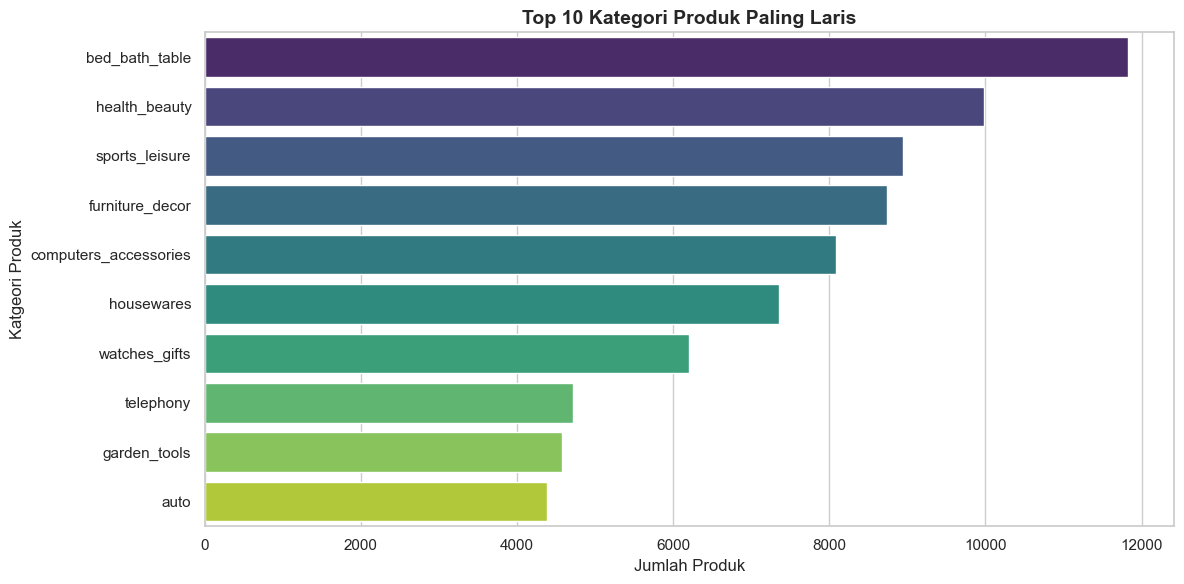

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\405165279.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = payment_counts.index, y = payment_counts.values, palette = 'magma')


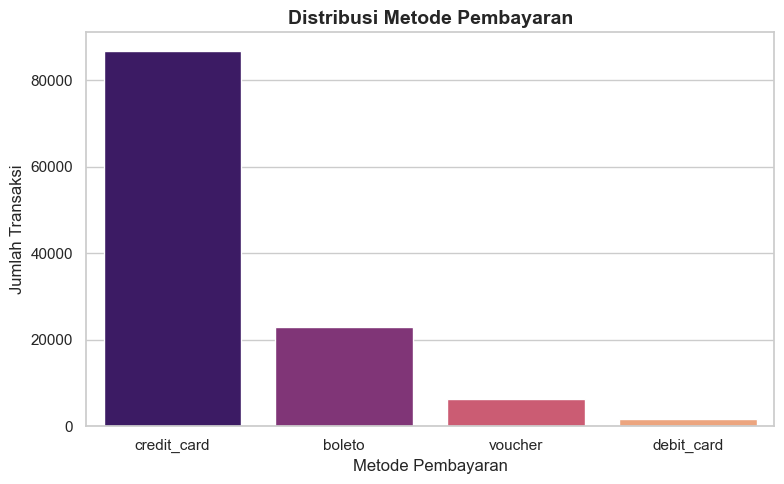

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

top_categories = df_main['product_category_name_english'].value_counts().head(10)
sns.barplot(x = top_categories.values, y = top_categories.index, palette = 'viridis')
plt.title('Top 10 Kategori Produk Paling Laris', fontsize = 14, fontweight = 'bold')
plt.xlabel('Jumlah Produk', fontsize = 12)
plt.ylabel('Katgeori Produk', fontsize = 12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

payment_counts = df_main['payment_type'].value_counts()
sns.barplot(x = payment_counts.index, y = payment_counts.values, palette = 'magma')
plt.title('Distribusi Metode Pembayaran', fontsize = 14, fontweight = 'bold')
plt.xlabel('Metode Pembayaran', fontsize = 12)
plt.ylabel('Jumlah Transaksi', fontsize = 12)
plt.tight_layout()
plt.show()



ANALISIS TREN WAKTU (TIME SERIES ANALYSIS)

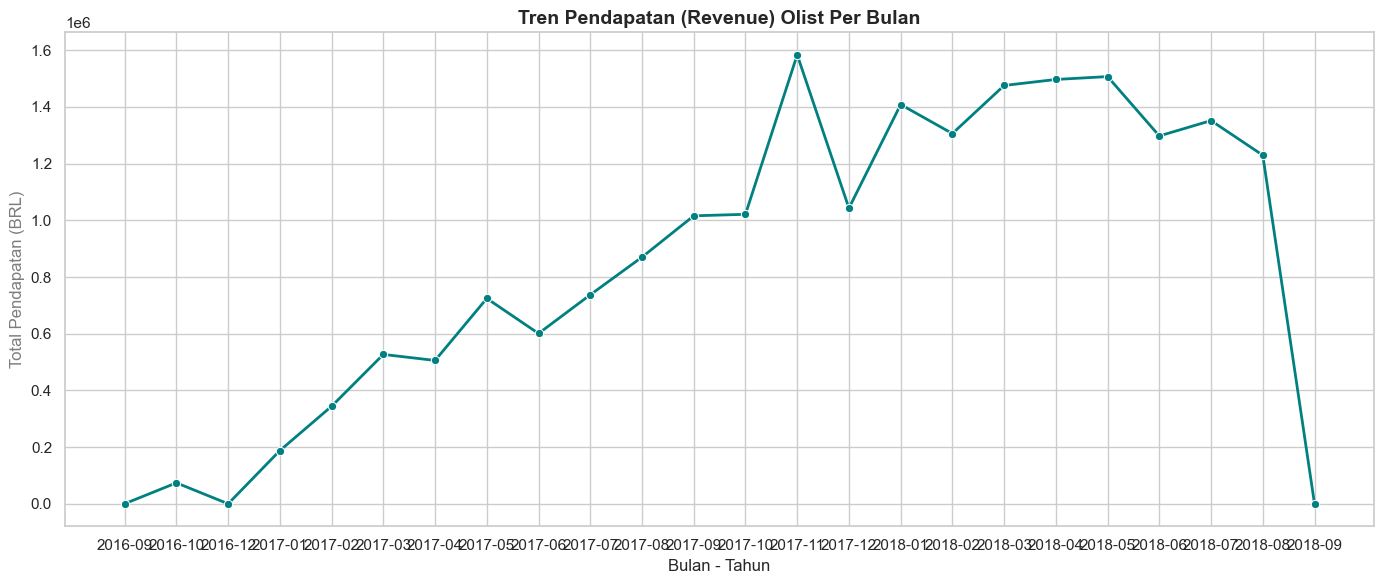

In [7]:
df_main['order_month_year'] = df_main['order_purchase_timestamp'].dt.to_period('M')

monthly_revenue = df_main.groupby('order_month_year')['payment_value'].sum().reset_index()

monthly_revenue['order_month_year'] = monthly_revenue['order_month_year'].astype(str)

plt.figure(figsize = (14, 6))
sns.lineplot(x = 'order_month_year', y = 'payment_value', data = monthly_revenue, marker = 'o', color = 'teal', linewidth = 2)
plt.title('Tren Pendapatan (Revenue) Olist Per Bulan', fontsize = 14, fontweight = 'bold')
plt.xlabel('Bulan - Tahun', fontsize = 12)
plt.ylabel('Total Pendapatan (BRL)', alpha = 0.6)
plt.tight_layout()
plt.show()

ANALISIS SEBARAN DEOGRAFI PELANGGAN

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\168025350.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = top_cities.values, y = top_cities.index, palette = 'crest')


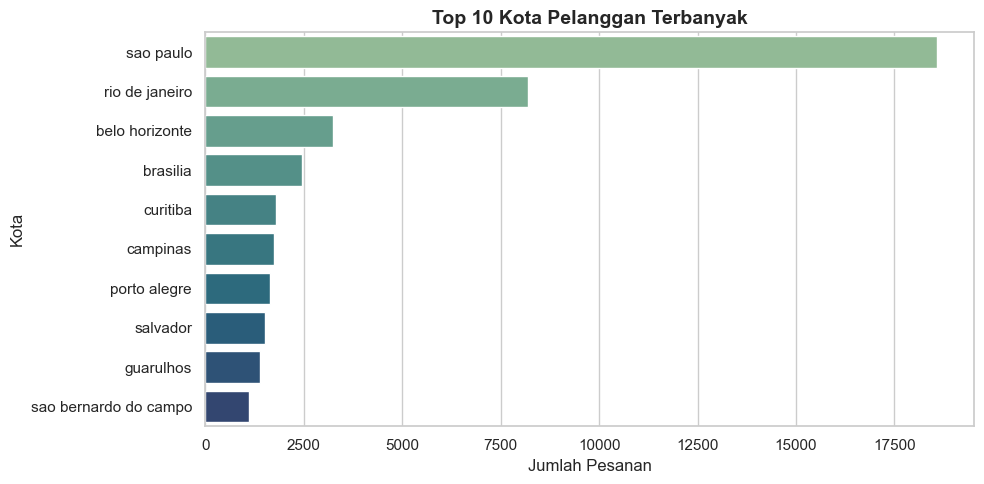

In [8]:
plt.figure(figsize = (10, 5))
top_cities = df_main['customer_city'].value_counts().head(10)
sns.barplot(x = top_cities.values, y = top_cities.index, palette = 'crest')
plt.title('Top 10 Kota Pelanggan Terbanyak', fontsize = 14, fontweight = 'bold')
plt.xlabel('Jumlah Pesanan', fontsize = 12)
plt.ylabel('Kota', fontsize = 12)
plt.tight_layout()
plt.show()

melakukan Segmentasi Pelanggan menggunakan Analisis RFM (Recency, Frequency, Monetary). 

Metode ini mengelompokkan pelanggan berdasarkan:

1. Recency: Kapan terakhir kali pelanggan berbelanja (dalam hari).
2. Frequency: Seberapa sering pelanggan melakukan transaksi.
3. Monetary: Total uang yang dihabiskan oleh pelanggan.

In [9]:
import datetime as dt

snapshot_date = df_main['order_purchase_timestamp'].max() + dt.timedelta(days = 1)

rfm = df_main.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,
    'order_id': 'nunique',
    'payment_value': 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']

print("Statistik Deskriptif Metrik RFM: ")
print(rfm.describe())
print('\n Sampel 5 Pelanggan Pertama: ')
print(rfm.head())

Statistik Deskriptif Metrik RFM: 
            Recency     Frequency       Monetary
count  95420.000000  95420.000000   95420.000000
mean     243.600377      1.034018     212.828911
std      153.160320      0.211234     641.760089
min        1.000000      1.000000       0.000000
25%      119.000000      1.000000      63.907500
50%      224.000000      1.000000     113.150000
75%      353.000000      1.000000     202.542500
max      729.000000     16.000000  109312.640000

 Sampel 5 Pelanggan Pertama: 
                 customer_unique_id  Recency  Frequency  Monetary
0  0000366f3b9a7992bf8c76cfdf3221e2      116          1    141.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f      119          1     27.19
2  0000f46a3911fa3c0805444483337064      542          1     86.22
3  0000f6ccb0745a6a4b88665a16c9f078      326          1     43.62
4  0004aac84e0df4da2b147fca70cf8255      293          1    196.89


Memberikan Skor RFM (RFM Scoring)

In [10]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], q = 4, labels = [4, 3, 2, 1])

rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method = 'first'), q = 4, labels = [1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels = [1, 2, 3, 4])

rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

rfm['RFM_Score'] = rfm['R_Score'].astype(int) + rfm['F_Score'].astype(int) + rfm['M_Score'].astype(int)

print(rfm[['customer_unique_id', 'Recency', 'Frequency', 'Monetary', 'RFM_Segment', 'RFM_Score']].head(10))

                 customer_unique_id  Recency  Frequency  Monetary RFM_Segment  \
0  0000366f3b9a7992bf8c76cfdf3221e2      116          1    141.90         413   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      119          1     27.19         411   
2  0000f46a3911fa3c0805444483337064      542          1     86.22         112   
3  0000f6ccb0745a6a4b88665a16c9f078      326          1     43.62         211   
4  0004aac84e0df4da2b147fca70cf8255      293          1    196.89         213   
5  0004bd2a26a76fe21f786e4fbd80607f      151          1    166.98         313   
6  00050ab1314c0e55a6ca13cf7181fecf      136          1     35.38         311   
7  00053a61a98854899e70ed204dd4bafe      187          1    838.36         314   
8  0005e1862207bf6ccc02e4228effd9a0      548          1    150.12         113   
9  0005ef4cd20d2893f0d9fbd94d3c0d97      175          1    129.76         313   

   RFM_Score  
0          8  
1          6  
2          4  
3          4  
4          6  
5          7  
6  

Menerjemahkan angka angka RFM_Score kedalam Kategori Segmen Bisnis

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\2479055603.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = segment_counts.values, y = segment_counts.index, palette = 'mako')


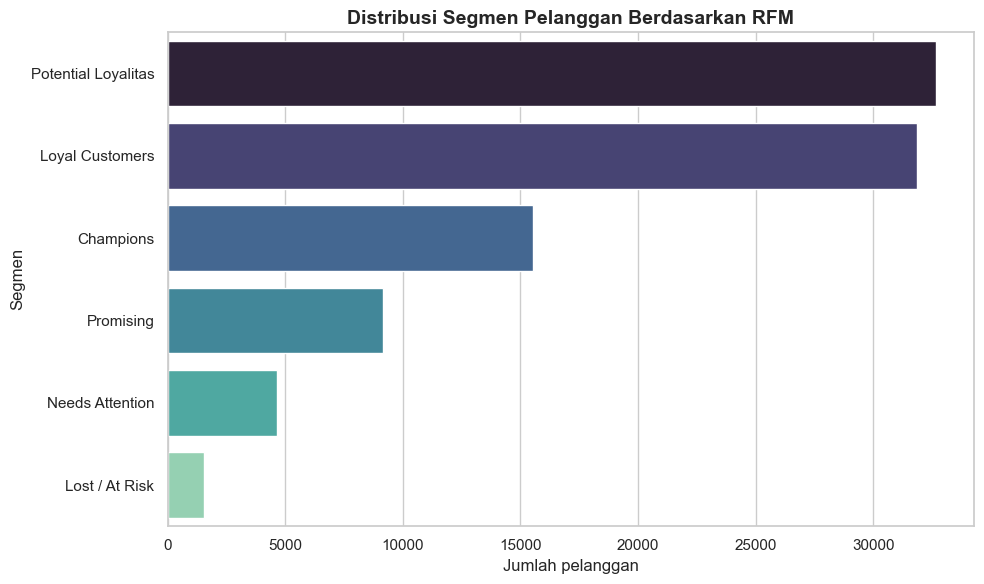

In [11]:
def segment_customer(df):
    if df['RFM_Score'] >= 10:
        return 'Champions'
    elif df['RFM_Score'] >= 8:
        return 'Loyal Customers'
    elif df['RFM_Score'] >= 6:
        return 'Potential Loyalitas'
    elif df['RFM_Score'] >= 5:
        return 'Promising'
    elif df['RFM_Score'] >= 4:
        return 'Needs Attention'
    else:
        return 'Lost / At Risk'
    
rfm['Customer_Segment'] = rfm.apply(segment_customer, axis = 1)

plt.figure(figsize = (10, 6))
segment_counts = rfm['Customer_Segment'].value_counts()
sns.barplot(x = segment_counts.values, y = segment_counts.index, palette = 'mako')
plt.title('Distribusi Segmen Pelanggan Berdasarkan RFM', fontsize = 14, fontweight = 'bold')
plt.xlabel('Jumlah pelanggan', fontsize = 12)
plt.ylabel('Segmen', fontsize = 12)
plt.tight_layout()
plt.show()

PEMODELAN MACHINE LEARNING

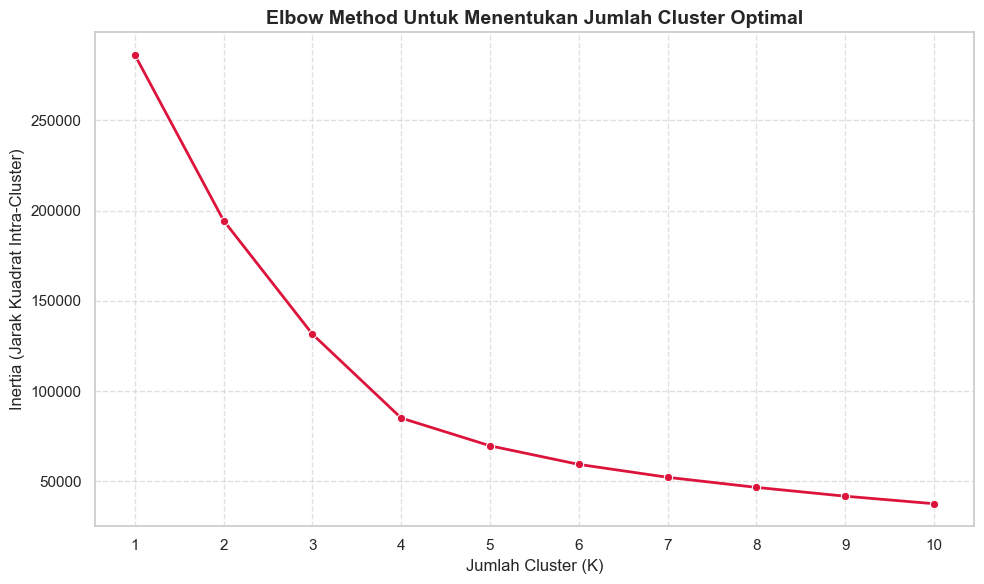

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np

rfm_ml = rfm[['Recency', 'Frequency', 'Monetary']]
rfm_log = rfm_ml.apply(lambda x: np.log1p(x))

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
sns.lineplot(x = list(K), y = inertia, marker = 'o', color = 'crimson', linewidth = 2)
plt.title('Elbow Method Untuk Menentukan Jumlah Cluster Optimal', fontsize = 14, fontweight = 'bold')
plt.xlabel('Jumlah Cluster (K)', fontsize = 12)
plt.ylabel('Inertia (Jarak Kuadrat Intra-Cluster)', fontsize = 12)
plt.xticks(K)
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.tight_layout()
plt.show()


mengaplikasikan algoritma K-Means dengan nilai k=4 ke dalam data, mengekstrak profil rata-rata dari setiap cluster, dan memvisualisasikan distribusinya.

Karakteristik Rata-rata Per Cluster (K_Means): 
            Recency  Frequency  Monetary  Jumlah_Pelanggan
ML_Cluster                                                
0            275.58       1.00    465.23             27409
1            299.50       1.00     77.53             47086
2             51.62       1.00    143.47             18012
3            226.20       2.11    453.86              2913


C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\626820726.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax = axes[0], x = 'ML_Cluster', y = 'Recency', data = rfm, palette = 'viridis')
C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\626820726.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax = axes[1], x = 'ML_Cluster', y = 'Frequency', data = rfm, palette = 'viridis')
C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\626820726.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax = axes[2], x = 'ML_Clu

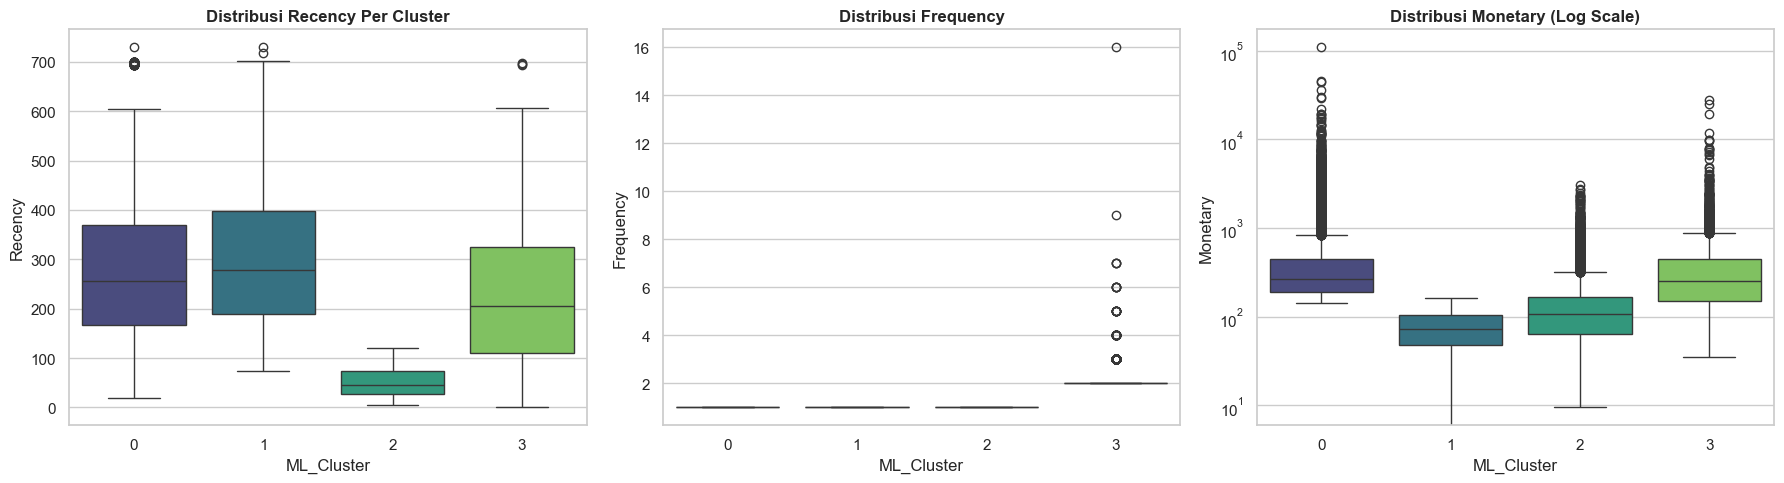

In [17]:
kmeans_model = KMeans(n_clusters = 4, random_state = 42, n_init = 10)

rfm['ML_Cluster'] = kmeans_model.fit_predict(rfm_scaled)

cluster_summary = rfm.groupby('ML_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'customer_unique_id': 'count'
}).rename(columns ={'customer_unique_id': 'Jumlah_Pelanggan'}).round(2)

print('Karakteristik Rata-rata Per Cluster (K_Means): ')
print(cluster_summary)

fig, axes = plt.subplots(1, 3, figsize = (18, 5))

sns.boxplot(ax = axes[0], x = 'ML_Cluster', y = 'Recency', data = rfm, palette = 'viridis')
axes[0].set_title('Distribusi Recency Per Cluster', fontweight = 'bold')

sns.boxplot(ax = axes[1], x = 'ML_Cluster', y = 'Frequency', data = rfm, palette = 'viridis')
axes[1].set_title('Distribusi Frequency', fontweight = 'bold')

sns.boxplot(ax = axes[2], x = 'ML_Cluster', y = 'Monetary', data = rfm, palette = 'viridis')
axes[2].set_yscale('log')
axes[2].set_title('Distribusi Monetary (Log Scale)', fontweight = 'bold')

plt.tight_layout()
plt.show()

Interpretasi :

1. Cluster 0 (Lost Big Spenders): Berbelanja sangat lama (Recency ~275 hari) tetapi menghabiskan uang paling banyak (Monetary rata-rata ~465 BRL). Mereka adalah mantan VIP yang perlu dirayu kembali dengan diskon besar.
2. Cluster 1 (Lost Cheap Customers): Kelompok terbesar (47.086 pelanggan) yang sudah lama pergi (Recency ~299 hari) dan hanya berbelanja sedikit (~77 BRL). Kelompok ini kurang diprioritaskan untuk di-retensi.
3. Cluster 2 (Recent/New Customers): Pelanggan yang baru saja berbelanja (Recency paling rendah, ~51 hari) dengan nilai belanja menengah. Mereka adalah target utama untuk kampanye email follow-up.
4. Cluster 3 (Loyal Customers): Kelompok terkecil namun paling berharga. Mereka adalah satu-satunya kelompok dengan rata-rata Frequency > 1 (berbelanja lebih dari sekali) dan nilai Monetary tinggi (~453 BRL).

memberikan nama (label) pada cluster tersebut, memvisualisasikan ukuran masing-masing cluster, dan menyimpan hasil akhirnya.

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9624\1411112364.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = ml_segment_counts.values, y = ml_segment_counts.index, palette = 'rocket')


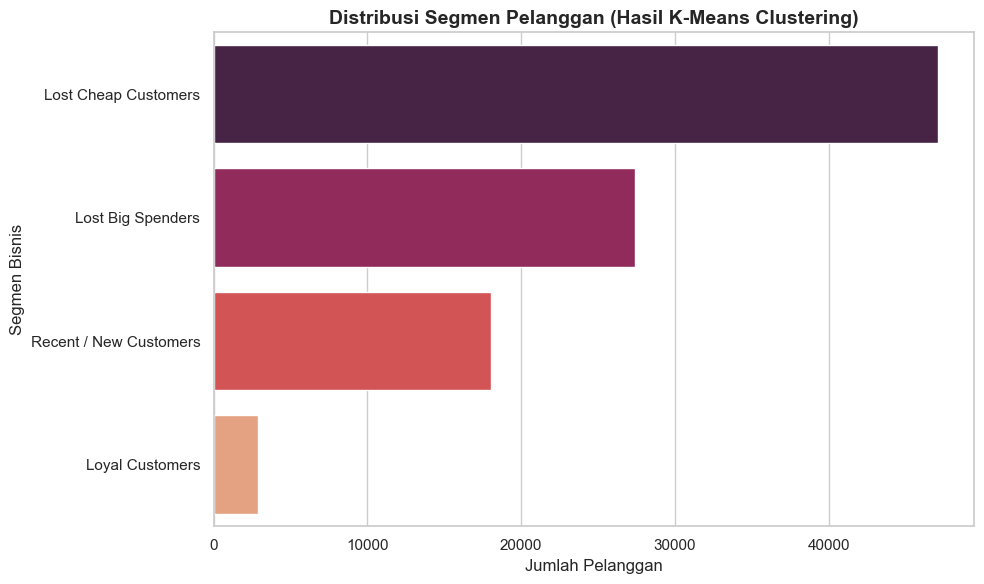

In [23]:
cluster_labels = {
    0: 'Lost Big Spenders',
    1: 'Lost Cheap Customers',
    2: 'Recent / New Customers',
    3: 'Loyal Customers'
}
rfm['ML_Segment_Name'] = rfm['ML_Cluster'].map(cluster_labels)

plt.figure(figsize = (10, 6))
ml_segment_counts = rfm['ML_Segment_Name'].value_counts()
sns.barplot(x = ml_segment_counts.values, y = ml_segment_counts.index, palette = 'rocket')
plt.title('Distribusi Segmen Pelanggan (Hasil K-Means Clustering)', fontsize = 14, fontweight = 'bold')
plt.xlabel('Jumlah Pelanggan', fontsize = 12)
plt.ylabel('Segmen Bisnis', fontsize = 12)
plt.tight_layout()
plt.show()